In [108]:
%pip install -q dataretrieval scikit-learn pandas matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataretrieval import waterdata

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import joblib
import os

In [110]:
SITE = "USGS-03497300" # Little River above Townsend, TN
START_YEAR, END_YEAR = 2020, 2025
LOCAL_TZ = "America/New_York" # timezone

ANOMALY_PERCENTILE = 99.5
K = 12 #num of clusters
SEASON_WEIGHT = 3 # How strongly to match each hour with clusters from same season/time of day.
HOUR_WEIGHT = 2

TEMP, FLOW = "00010", "00060" # USGS codes: water temp, streamflow
CACHE_FILE = "little_river_hourly.csv" # where the data is saved so we don't have to redownload

In [111]:
def download_hourly(code_, name):
    parts = []
    for yr in range(START_YEAR, END_YEAR + 1):
        try:
            c, _ = waterdata.get_continuous(monitoring_location_id=SITE, parameter_code=code_,
                                            time=f"{yr}-01-01/{yr}-12-31")
        except Exception as e:
            print(f"  {name} {yr}: failed ({type(e).__name__}: {e})")
            continue
        if c.empty:
            print(f"  {name} {yr}: no data")
            continue
        s = pd.to_numeric(c["value"], errors="coerce")
        t = pd.to_datetime(c["time"], utc=True)
        s.index = t.dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
        hourly = s.resample("h").mean()
        parts.append(hourly)
        print(f"  {name} {yr}: {len(c):,} readings -> {hourly.notna().sum():,} hours")
    if not parts:
        raise ValueError(f"No {name} data downloaded for {SITE}.")
    s = pd.concat(parts)
    return s[~s.index.duplicated()]

if os.path.exists(CACHE_FILE):
    df = pd.read_csv(CACHE_FILE, index_col="time", parse_dates=True)
    print(f"Loaded {len(df):,} hours from {CACHE_FILE}")
else:
    print("Downloading temperature...")
    temp = download_hourly(TEMP, "temperature")
    print("Downloading streamflow...")
    flow = download_hourly(FLOW, "streamflow")
    df = pd.DataFrame({"temp_C": temp, "flow_cfs": flow})
    df.index.name = "time"
    df.to_csv(CACHE_FILE)
    print(f"Saved {len(df):,} hours to {CACHE_FILE}")

df.head()

Loaded 52,470 hours from little_river_hourly.csv


,temp_C,flow_cfs
time,,
2019-12-31 19:00:00,7.475,291.000000
2019-12-31 20:00:00,7.375,292.000000
2019-12-31 21:00:00,7.250,283.000000
2019-12-31 22:00:00,7.150,288.333333
2019-12-31 23:00:00,7.000,284.000000


In [112]:
print("Missing hours before cleaning:")
print(df.isna().sum(), "\n")

df = df.dropna()
df = df[df["temp_C"].between(-1, 40) & (df["flow_cfs"] > 0)]

print(f"{len(df):,} hours with both temperature and flow "
      f"({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
df.describe().round(2)

Missing hours before cleaning:
temp_C      551
flow_cfs      9
dtype: int64 

51,919 hours with both temperature and flow (2019-12-31 to 2025-12-30)


,temp_C,flow_cfs
count,51919.00,51919.00
mean,13.48,297.27
std,5.89,371.66
min,-0.05,18.32
25%,8.65,110.50
50%,13.48,190.75
75%,18.73,344.25
max,25.90,9447.50


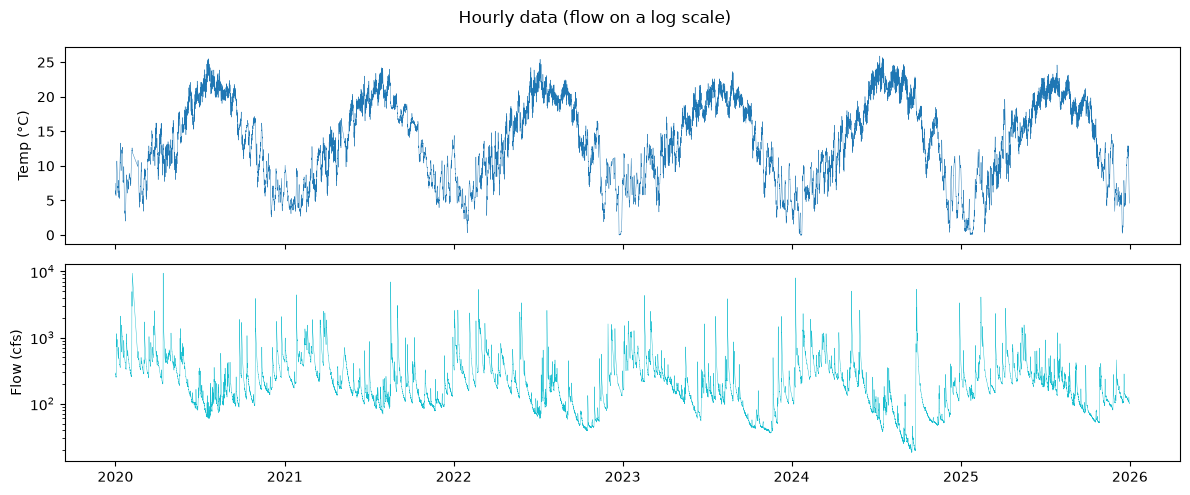

In [113]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(df.index, df["temp_C"], lw=0.3); ax[0].set_ylabel("Temp (°C)")
ax[1].plot(df.index, df["flow_cfs"], lw=0.3, color="tab:cyan"); ax[1].set_ylabel("Flow (cfs)")
ax[1].set_yscale("log")
plt.suptitle("Hourly data (flow on a log scale)"); plt.tight_layout(); plt.show()

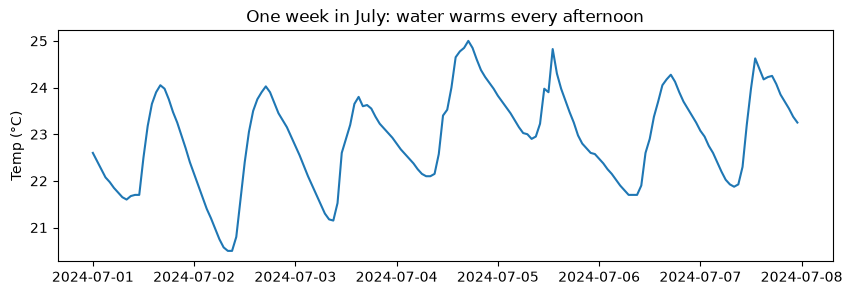

In [114]:
week = df.loc["2024-07-01":"2024-07-07"]
if len(week):
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(week.index, week["temp_C"])
    ax.set(title="One week in July: water warms every afternoon", ylabel="Temp (°C)")
    plt.show()

In [115]:
def make_features(temp, flow, times):
    t = pd.DatetimeIndex(times)
    doy = t.dayofyear.values
    hr = t.hour.values + t.minute.values / 60
    return np.column_stack([np.asarray(temp, float),
                            np.log10(np.asarray(flow, float)),
                            np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25),
                            np.sin(2 * np.pi * hr / 24),      np.cos(2 * np.pi * hr / 24)])

WEIGHTS = np.array([1, 1, SEASON_WEIGHT, SEASON_WEIGHT, HOUR_WEIGHT, HOUR_WEIGHT])

X = make_features(df["temp_C"], df["flow_cfs"], df.index)
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X) * WEIGHTS
print("Feature matrix:", X_scaled.shape)

Feature matrix: (51919, 6)


In [116]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = kmeans.labels_

def deviations(X_scaled, kmeans):
    """How far each hour's temperature and flow are from its nearest cluster center (scaled units)."""
    nearest = kmeans.predict(X_scaled)
    return np.abs(X_scaled - kmeans.cluster_centers_[nearest])[:, :2]   

def label(over):
    return np.select([over[:, 0] & over[:, 1], over[:, 0], over[:, 1]],
                     ["temp + flow", "temperature", "flow"], default="")

dev = deviations(X_scaled, kmeans)
thresholds = np.percentile(dev, ANOMALY_PERCENTILE, axis=0)
over = dev > thresholds

df["score"] = (dev / thresholds).max(axis=1)      
df["anomaly"] = over.any(axis=1)
df["anomaly_type"] = label(over)

print(f"Cutoffs (scaled units): temperature {thresholds[0]:.2f}, flow {thresholds[1]:.2f}")
print(f"Flagged {df['anomaly'].sum():,} of {len(df):,} hours")
print(df.loc[df["anomaly"], "anomaly_type"].value_counts().to_string())

Cutoffs (scaled units): temperature 1.37, flow 2.78
Flagged 519 of 51,919 hours
anomaly_type
flow           260
temperature    259


In [117]:
flagged = df[df["anomaly"]].copy()
new_event = flagged.index.to_series().diff() > pd.Timedelta(hours=6)
flagged["event"] = new_event.cumsum()

events = flagged.groupby("event").agg(
    start=("score", lambda s: s.index.min()),
    end=("score", lambda s: s.index.max()),
    hours=("score", "size"),
    type=("anomaly_type", lambda s: s.value_counts().index[0]),
    max_score=("score", "max"),
    peak_temp_C=("temp_C", "max"),
    min_temp_C=("temp_C", "min"),
    peak_flow_cfs=("flow_cfs", "max"),
).round({"max_score": 2, "peak_temp_C": 1, "min_temp_C": 1, "peak_flow_cfs": 0})
print(f"{len(events)} anomaly events")
events.sort_values("max_score", ascending=False).head(20)

113 anomaly events


,start,end,hours,type,max_score,peak_temp_C,min_temp_C,peak_flow_cfs
event,,,,,,,,
66,2024-09-26 07:00:00,2024-09-28 03:00:00,44,flow,1.65,17.9,16.8,5408.0
18,2021-08-17 16:00:00,2021-08-18 13:00:00,20,flow,1.62,19.3,18.7,6945.0
9,2020-10-29 09:00:00,2020-10-30 18:00:00,31,flow,1.51,16.9,12.7,3910.0
2,2020-04-13 03:00:00,2020-04-13 10:00:00,8,flow,1.45,13.0,12.3,9448.0
44,2023-08-15 05:00:00,2023-08-15 21:00:00,17,flow,1.42,19.9,18.6,3865.0
61,2024-09-23 11:00:00,2024-09-23 12:00:00,2,temperature,1.41,22.4,21.7,21.0
75,2024-12-06 22:00:00,2024-12-07 00:00:00,3,temperature,1.40,1.3,1.0,68.0
63,2024-09-24 11:00:00,2024-09-24 12:00:00,2,temperature,1.40,22.4,22.0,23.0
51,2024-01-09 11:00:00,2024-01-09 22:00:00,12,flow,1.39,8.6,7.4,7992.0


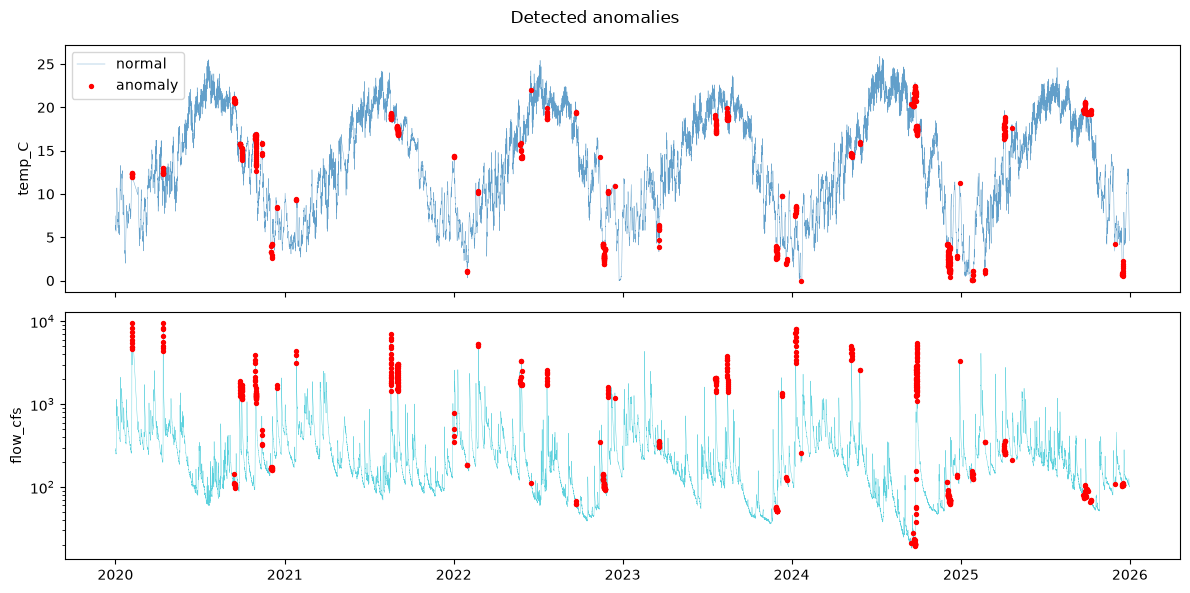

In [118]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for a, col, color in [(ax[0], "temp_C", "tab:blue"), (ax[1], "flow_cfs", "tab:cyan")]:
    a.plot(df.index, df[col], lw=0.3, color=color, alpha=0.7, label="normal")
    a.scatter(flagged.index, flagged[col], color="red", s=8, zorder=3, label="anomaly")
    a.set_ylabel(col)
ax[1].set_yscale("log")
ax[0].legend(loc="upper left")
plt.suptitle("Detected anomalies"); plt.tight_layout(); plt.show()

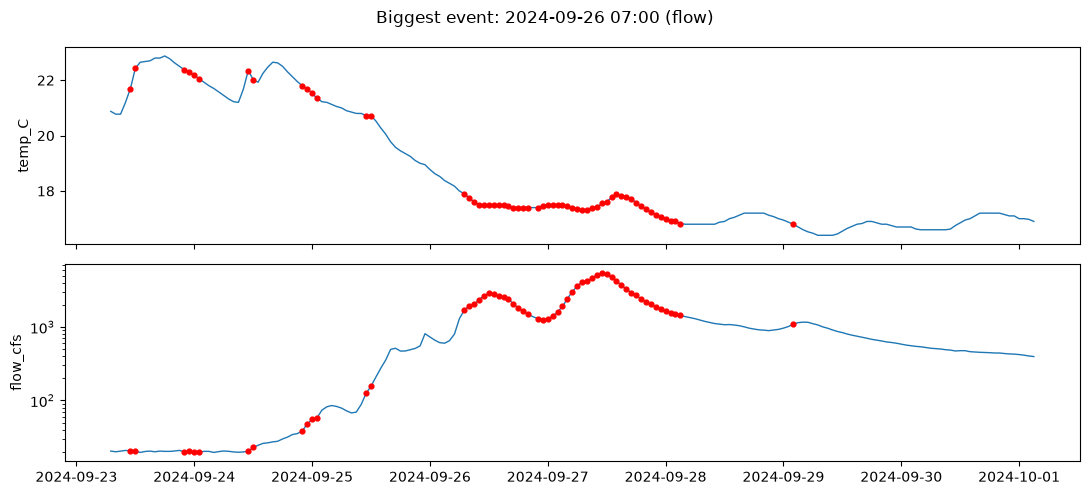

In [119]:
top = events.sort_values("max_score", ascending=False).iloc[0]
window = df.loc[top["start"] - pd.Timedelta(days=3): top["end"] + pd.Timedelta(days=3)]
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for a, col in zip(ax, ["temp_C", "flow_cfs"]):
    a.plot(window.index, window[col], lw=1)
    w = window[window["anomaly"]]
    a.scatter(w.index, w[col], color="red", s=12, zorder=3)
    a.set_ylabel(col)
ax[1].set_yscale("log")
plt.suptitle(f"Biggest event: {top['start']:%Y-%m-%d %H:%M} ({top['type']})"); plt.tight_layout(); plt.show()

In [120]:
lo, hi = 0.25, 99.75
t_lo, t_hi = np.percentile(df["temp_C"], [lo, hi])
f_lo, f_hi = np.percentile(df["flow_cfs"], [lo, hi])
df["rule_flag"] = ~df["temp_C"].between(t_lo, t_hi) | ~df["flow_cfs"].between(f_lo, f_hi)

print("Hours flagged by fixed limits:", df["rule_flag"].sum())
print("Hours flagged by the model:   ", df["anomaly"].sum())
print("Flagged by both:              ", (df["anomaly"] & df["rule_flag"]).sum())
print("Model only (missed by rules): ", (df["anomaly"] & ~df["rule_flag"]).sum())

Hours flagged by fixed limits: 490
Hours flagged by the model:    519
Flagged by both:               97
Model only (missed by rules):  422
